## Radio Astronomy Imaging
Jupyter Notebook, code written by:  
6344569 Mathijs Bos  
5866642 Tycho Brouwer  

### Initial Setup

In [3]:
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
np.set_printoptions(suppress=True)

mat = scipy.io.loadmat('lofar_data/lofar_DSP_data_1.mat')

print([k for k in mat.keys() if not k.startswith("__")])
ans = mat["ans"]
freq = np.squeeze(mat["freq"])
poslocal = mat["poslocal"]
t_obs = np.squeeze(mat["t_obs_matlab"])
lon = np.squeeze(mat["lon"])
lat = np.squeeze(mat["lat"])
Rh = mat["Rh"]

# print(poslocal.min(axis=0).round(4))
# print(poslocal.max(axis=0).round(4))
# print(np.ptp(poslocal, axis=0).round(4))

c = 299792458
p = len(Rh) # number of receiving elements
lambd = c / freq

x = poslocal[:, 1]
y = poslocal[:, 2]
dist = np.sqrt((x[:,None] - x[None, :])**2 + (y[:,None] - y[None,:])**2)

D = np.max(dist)

dl = 0.25 * lambd / D

l = np.arange(0, 1, dl)
l = np.concatenate((-np.flipud(l[2:]), l))

m = l.copy()

['ans', 'freq', 'poslocal', 't_obs_matlab', 'lon', 'lat', 'Rh']


### Periodogram Solution (classical beamforming)
This solution simply calculates:
$P = a^H R_h a$

In [4]:
L, M = np.meshgrid(l, m)
P = np.zeros((len(m), len(l)))
r = poslocal - poslocal.mean()
r = r[:, 0:2]

for i in range(len(m)):
    for j in range(len(l)):
        m0 = m[i]
        l0 = l[j]

        s = np.array([l0, m0])
        a = np.exp(-2j*np.pi/lambd * (r@s))
        P[i,j] = np.real(a.conj() @ Rh @ a)

Text(0, 0.5, 'y')

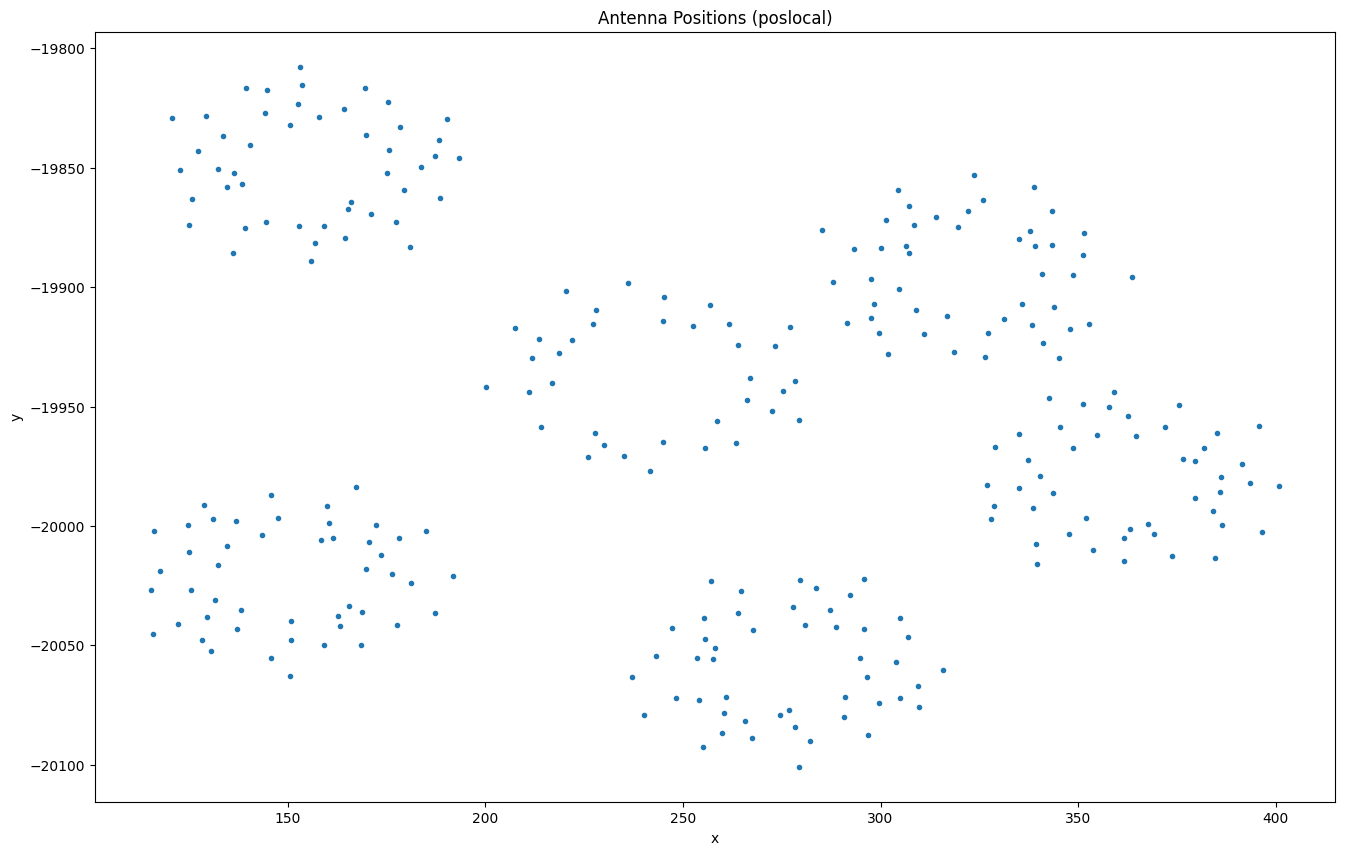

In [5]:
plt.figure(figsize=(16,10))
plt.plot(poslocal[:,0], poslocal[:,1], '.')
plt.title("Antenna Positions (poslocal)")
plt.xlabel("x")
plt.ylabel("y")

Text(0, 0.5, 'm')

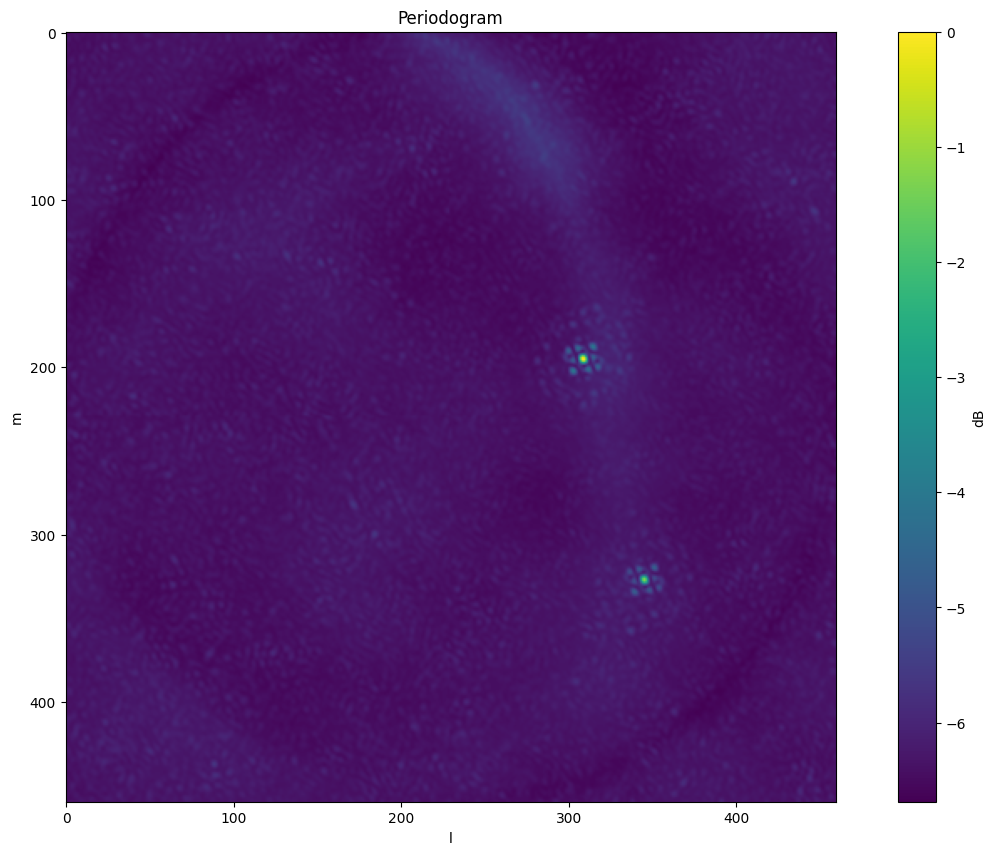

In [6]:
P_dB = 10 * np.log10(P / np.nanmax(P))

plt.figure(figsize=(16,10))
plt.imshow(P_dB)
plt.colorbar(label='dB')
plt.title("Periodogram")
plt.xlabel('l')
plt.ylabel('m')


### MVDR
$I'_D =  \sum^{K}_{k=1} 1/(a^H(S)\; \hat{R}^{-1}\; a(S)) $

In [ ]:
L, M = np.meshgrid(l, m)
P = np.zeros((len(m), len(l)))
r = poslocal - poslocal.mean()
r = r[:, 0:2]


for i in range(len(m)):
    for j in range(len(l)):
        s = np.array([l[j], m[i]])
        a = np.exp(-2j * np.pi / lambd * (r @ s))
        P[i, j] = 1/ np.real(np.conj(a).T @ np.linalg.solve(Rh, a))
        

Text(0, 0.5, 'm')

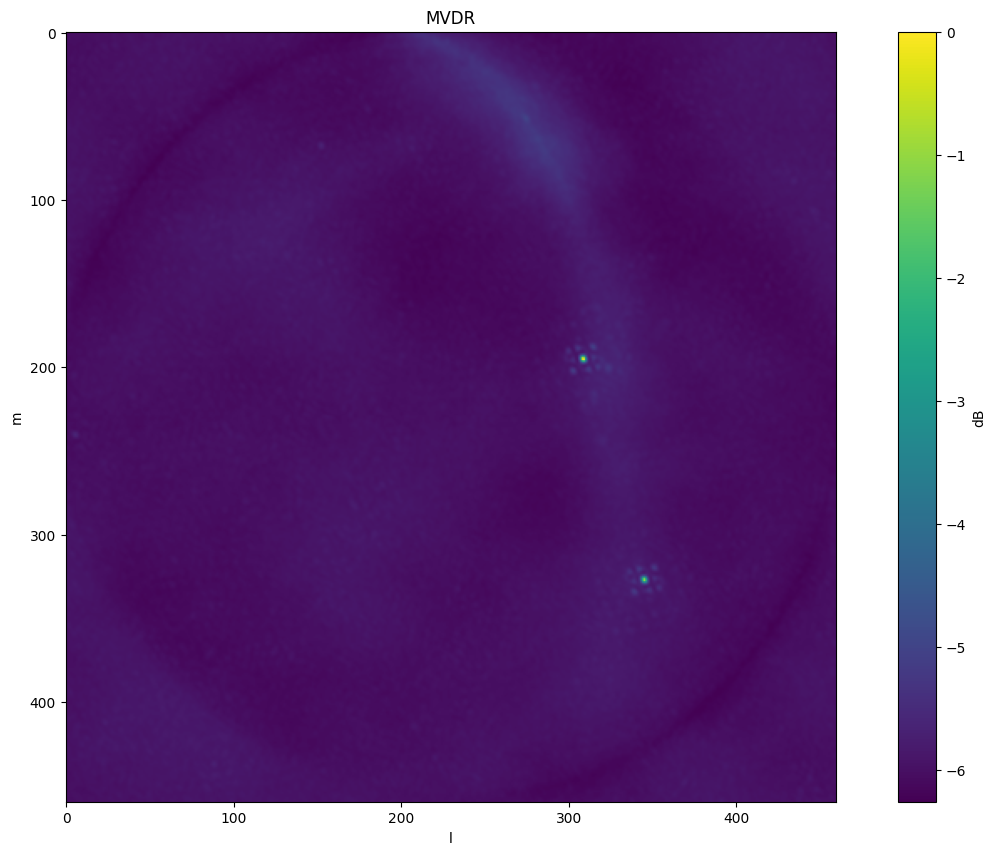

In [11]:
P_dB = 10 * np.log10(P / np.nanmax(P))

plt.figure(figsize=(16,10))
plt.imshow(P_dB)
plt.colorbar(label='dB')
plt.title("MVDR")
plt.xlabel('l')
plt.ylabel('m')

### MUSIC

### Adaptive Angular Response (AAR)

In [12]:
L, M = np.meshgrid(l, m)
P = np.zeros((len(m), len(l)))
r = poslocal - poslocal.mean()
r = r[:, 0:2]


for i in range(len(m)):
    for j in range(len(l)):
        s = np.array([l[j], m[i]])
        a = np.exp(-2j * np.pi / lambd * (r @ s))
        P[i, j] = (a.conj().T @ np.linalg.solve(Rh, a)) / (a.conj().T @ np.linalg.solve(Rh @ Rh, a))**2

C:\Users\tycho\AppData\Local\Temp\ipykernel_8968\2315083546.py:11: ComplexWarning: Casting complex values to real discards the imaginary part
  P[i, j] = (a.conj().T @ np.linalg.solve(Rh, a)) / (a.conj().T @ np.linalg.solve(Rh @ Rh, a))**2


Text(0, 0.5, 'm')

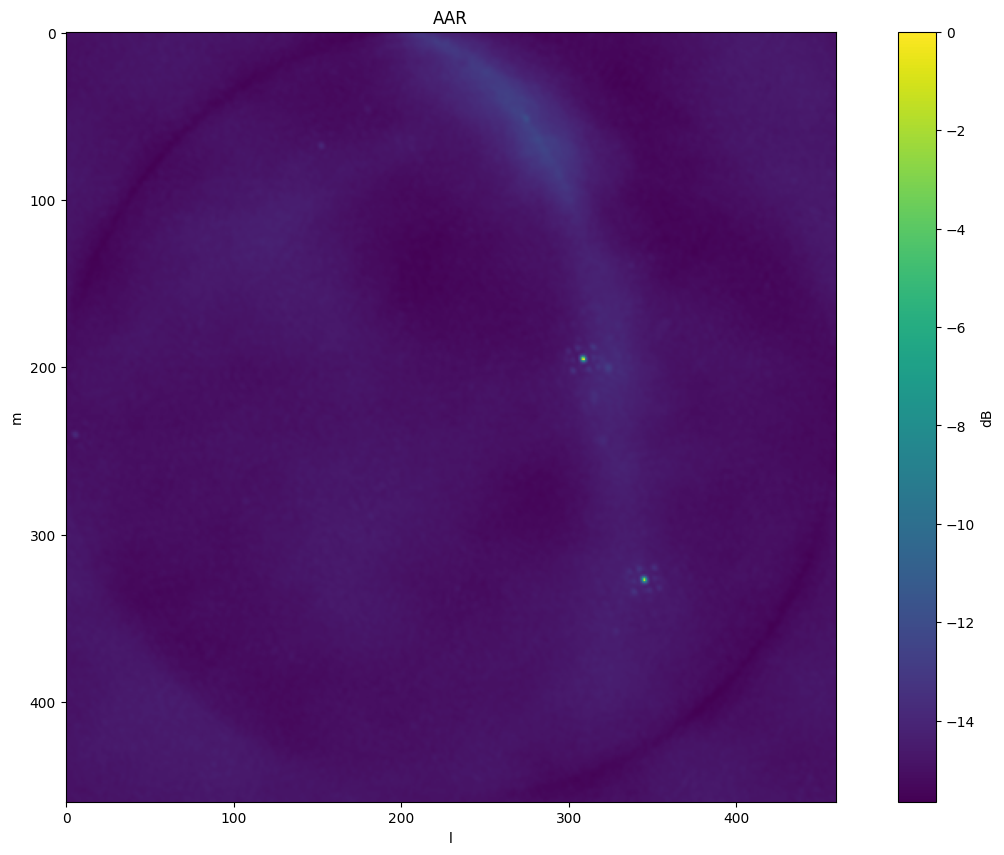

In [13]:
P_dB = 10 * np.log10(P / np.nanmax(P))

plt.figure(figsize=(16,10))
plt.imshow(P_dB)
plt.colorbar(label='dB')
plt.title("AAR")
plt.xlabel('l')
plt.ylabel('m')